# 33 · 优化、容量与泛化

公用基础路径：31 → 32 → 33 → 34，再进入搜索、广告或推荐。

**范围：小数组构造机制实验，CPU执行，无真实日志、无正式模型训练或业务收益主张。**

每节先预测 → 只改一个变量 → 运行 → 解释。首次从头执行，后续修改时重跑相关下游格。

## 优化的可控起点

对 L(w)=w² 做梯度下降。这里无数据泛化含义，仅隔离学习率。

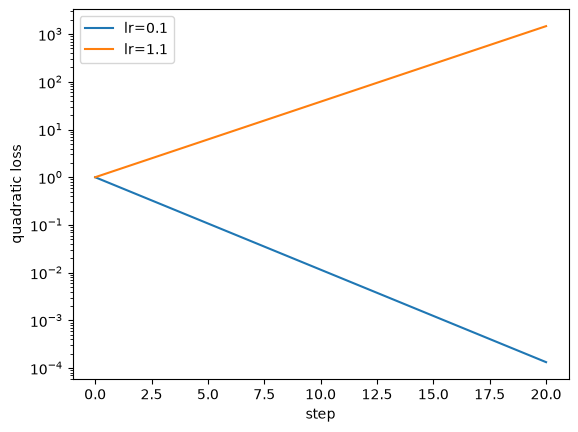

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from reclab.learning.foundations import quadratic_descent, polynomial_fit
curves = {lr: quadratic_descent(lr) for lr in [0.1, 1.1]}
assert curves[0.1][-1]**2 < curves[0.1][0]**2
assert curves[1.1][-1]**2 > curves[1.1][0]**2
for lr, values in curves.items():
    plt.semilogy(np.square(values), label=f'lr={lr}')
plt.xlabel('step'); plt.ylabel('quadratic loss'); plt.legend(); plt.show()

## 固定构造训练与选择集

真实函数为线性，训练标签含固定噪声；选择集来自同一函数的不同坐标。它不代表真实分布。先预测高阶模型训练误差。

In [2]:
train_x = np.linspace(-1, 1, 10)
noise = np.array([.1,-.2,.15,-.1,.2,-.15,.05,.12,-.18,.1])
train_y = 1 + 2*train_x + noise
select_x = np.linspace(-.95, .95, 80)
select_y = 1 + 2*select_x
assert train_x.shape == train_y.shape == (10,)

## 只改模型阶数

相同训练点与最小二乘求解器，比较1阶与9阶。没有使用选择标签拟合系数。

In [3]:
fits = {degree: polynomial_fit(train_x, train_y, select_x, degree) for degree in [1, 9]}
errors = {d: (np.mean((a-train_y)**2), np.mean((b-select_y)**2)) for d,(a,b) in fits.items()}
assert errors[9][0] < errors[1][0]
assert errors[9][1] > errors[1][1]
print('degree: (train MSE, select MSE)', errors)

degree: (train MSE, select MSE) {1: (np.float64(0.02034654545454546), np.float64(8.285834370750043e-05)), 9: (np.float64(6.981254151602715e-28), np.float64(0.35380856429606694))}


## 检查局部失败与评估边界

画出同一组预测。根据选择集选阶数后，不能再把它叫作未见审计集。

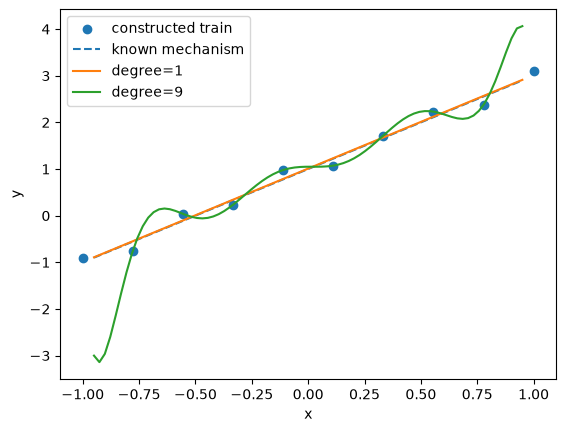

In [4]:
plt.scatter(train_x, train_y, label='constructed train')
plt.plot(select_x, select_y, '--', label='known mechanism')
for degree, (_, prediction) in fits.items():
    plt.plot(select_x, prediction, label=f'degree={degree}')
plt.xlabel('x'); plt.ylabel('y'); plt.legend(); plt.show()

## 解释练习

解释：训练误差更低为什么没有带来选择误差更低？如何保持一个真正独立的最终评估集？本例只对固定噪声成立，改变噪声种子前先写预测，不把一次结果推广成定律。

在下格记录预测、实际结果、差异原因与适用边界；保留失败结果。

In [5]:
reflection = {'预测': '', '结果': '', '解释与边界': ''}
reflection

{'预测': '', '结果': '', '解释与边界': ''}